# Part 3: Bivariate & Multivariate Analysis
**Course Notes Reference:** Parts 9 & 10

Topics covered:
1. Line plots for trends (`Year` vs `Sales`) & comparing multiple lines
2. Raw (`sns.lineplot` with 95% CI) vs Aggregated (`groupby().sum()`) line plots
3. Scatter plots with extra dimensions (`hue`, `size`, `style`, `alpha`)
4. Trend lines (`regplot`, `lmplot`) & Correlation (Pearson, Spearman, Kendall)
5. Count plot with `hue` & Crosstab / 100% Stacked Bar Chart
6. Correlation Heatmap (with `mask`, `annot`, `cmap='coolwarm'`) & Pivot-Table Heatmap
7. Pair Plot (`diag_kind='kde'`, `corner=True`) & Joint Plot (`scatter`, `hex`, `kde`, `reg`)


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_csv("vgsales.csv").dropna(subset=["Year", "Publisher"]).copy()
df["Year"] = df["Year"].astype(int)


## 1. Line Plots: Trends & Comparing Two Series


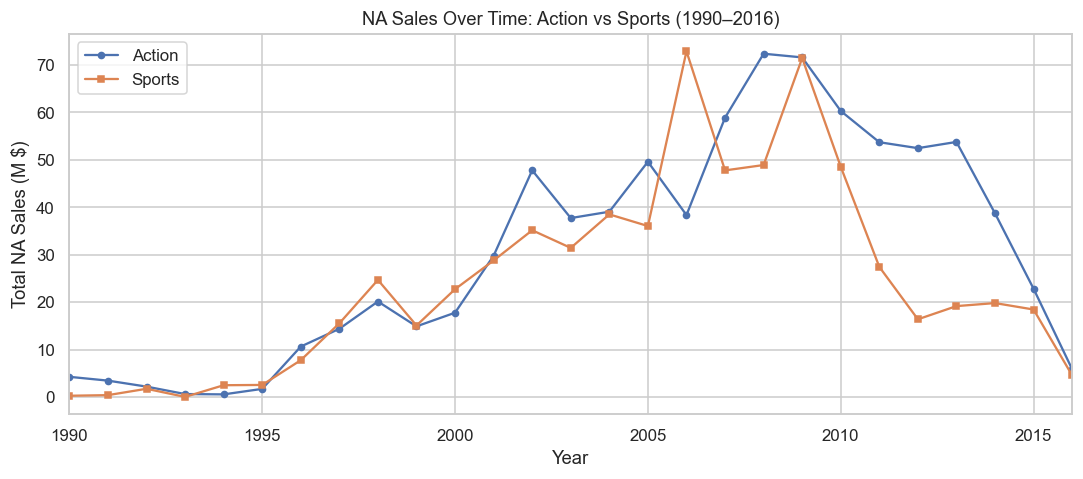

In [2]:
# Compare Sports vs Action total NA_Sales over years
action_yr = df[df["Genre"] == "Action"].groupby("Year")["NA_Sales"].sum()
sports_yr = df[df["Genre"] == "Sports"].groupby("Year")["NA_Sales"].sum()

plt.figure(figsize=(10, 4.5))
plt.plot(action_yr.index, action_yr.values, label="Action", marker="o", markersize=4)
plt.plot(sports_yr.index, sports_yr.values, label="Sports", marker="s", markersize=4)
plt.xlim(1990, 2016)
plt.title("NA Sales Over Time: Action vs Sports (1990–2016)")
plt.xlabel("Year")
plt.ylabel("Total NA Sales (M $)")
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()


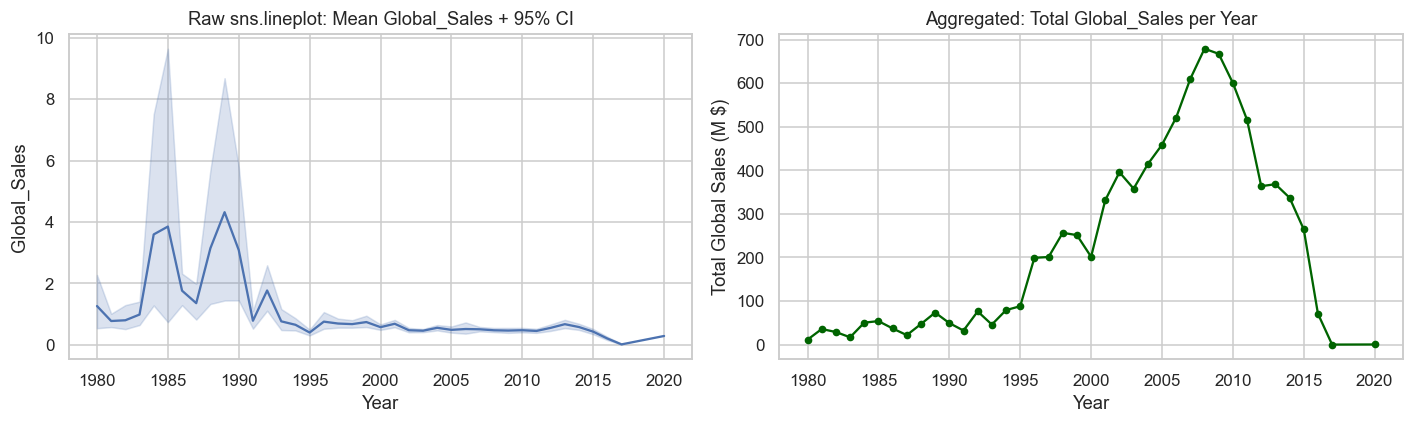

In [3]:
# Raw (mean + 95% CI) vs Aggregated (sum)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.lineplot(data=df, x="Year", y="Global_Sales", ax=axes[0])
axes[0].set_title("Raw sns.lineplot: Mean Global_Sales + 95% CI")

yearly_total = df.groupby("Year")["Global_Sales"].sum()
axes[1].plot(yearly_total.index, yearly_total.values, marker="o", markersize=4, color="darkgreen")
axes[1].set_title("Aggregated: Total Global_Sales per Year")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Total Global Sales (M $)")

plt.tight_layout()
plt.show()


## 2. Scatter Plots, Extra Dimensions & Trend Lines


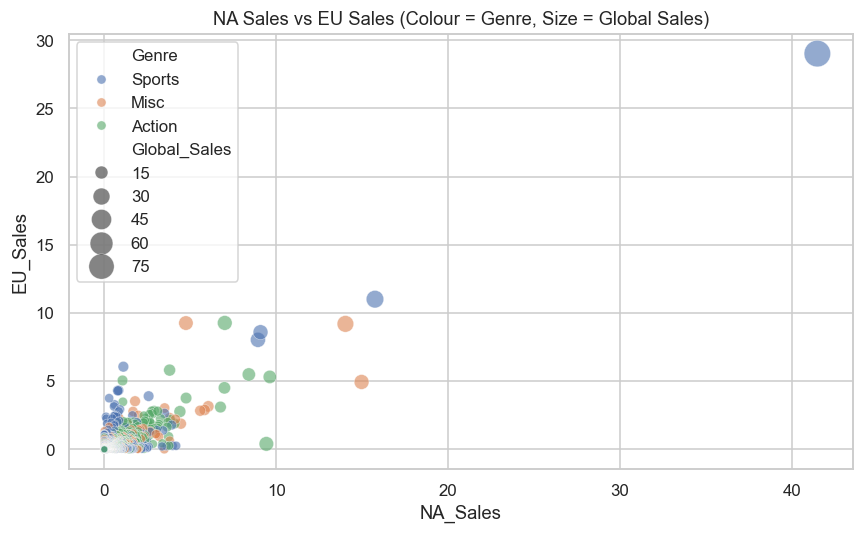

In [4]:
top3_genres = df["Genre"].value_counts().head(3).index
sub = df[df["Genre"].isin(top3_genres)]

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=sub, x="NA_Sales", y="EU_Sales",
    hue="Genre", size="Global_Sales", sizes=(20, 300), alpha=0.6
)
plt.title("NA Sales vs EU Sales (Colour = Genre, Size = Global Sales)")
plt.tight_layout()
plt.show()


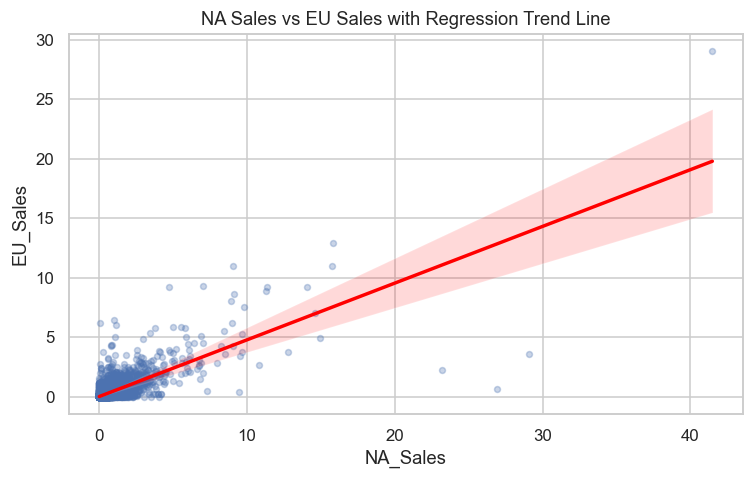

In [5]:
# Trend line with regplot
plt.figure(figsize=(7, 4.5))
sns.regplot(data=df, x="NA_Sales", y="EU_Sales", scatter_kws={"alpha": 0.3, "s": 15}, line_kws={"color": "red"})
plt.title("NA Sales vs EU Sales with Regression Trend Line")
plt.tight_layout()
plt.show()


## 3. Correlation (Pearson, Spearman, Kendall) & Heatmaps


In [6]:
sales_cols = ["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales", "Global_Sales"]
print("Pearson correlation:\n", df[sales_cols].corr(method="pearson").round(2))
print("\nSpearman correlation (robust to skew/outliers):\n", df[sales_cols].corr(method="spearman").round(2))


Pearson correlation:
               NA_Sales  EU_Sales  JP_Sales  Other_Sales  Global_Sales
NA_Sales          1.00      0.77      0.45         0.63          0.94
EU_Sales          0.77      1.00      0.44         0.73          0.90
JP_Sales          0.45      0.44      1.00         0.29          0.61
Other_Sales       0.63      0.73      0.29         1.00          0.75
Global_Sales      0.94      0.90      0.61         0.75          1.00

Spearman correlation (robust to skew/outliers):
               NA_Sales  EU_Sales  JP_Sales  Other_Sales  Global_Sales
NA_Sales          1.00      0.68     -0.23         0.77          0.79
EU_Sales          0.68      1.00     -0.18         0.77          0.70
JP_Sales         -0.23     -0.18      1.00        -0.07          0.16
Other_Sales       0.77      0.77     -0.07         1.00          0.81
Global_Sales      0.79      0.70      0.16         0.81          1.00


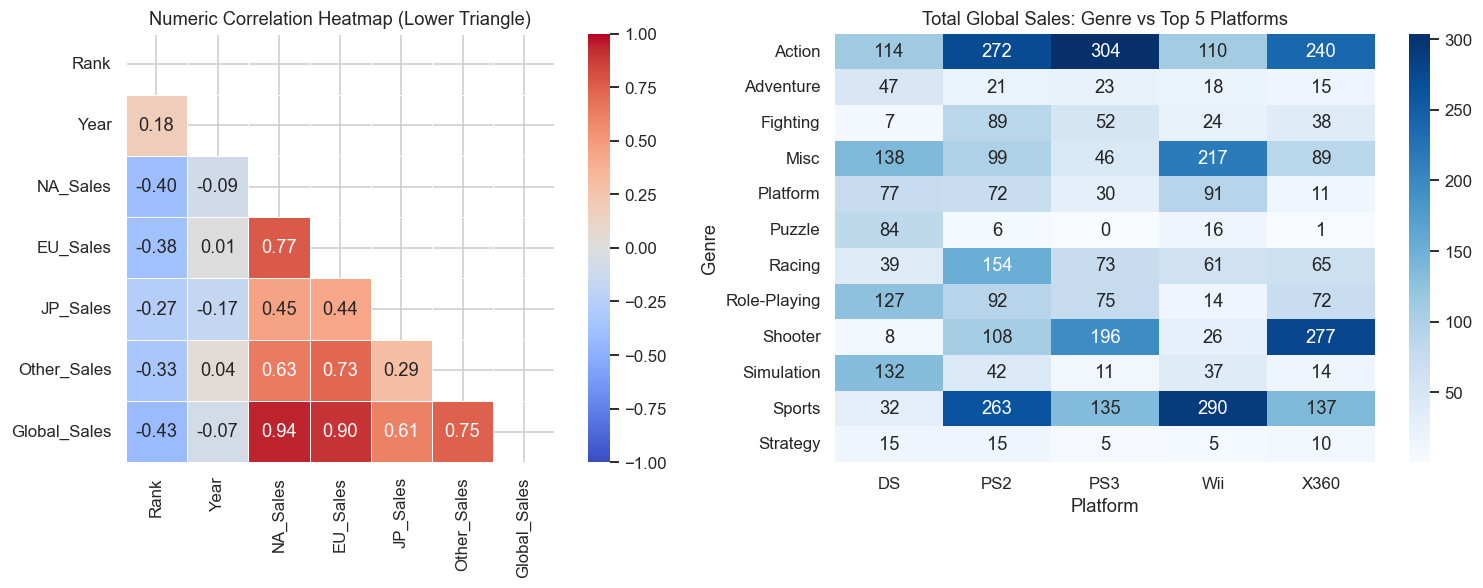

In [7]:
# Masked Correlation Heatmap + Pivot Table Heatmap
num_corr = df.select_dtypes(include="number").corr()
mask = np.triu(np.ones_like(num_corr, dtype=bool))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.heatmap(
    num_corr, annot=True, fmt=".2f", cmap="coolwarm",
    vmin=-1, vmax=1, linewidths=0.5, mask=mask, square=True, ax=axes[0]
)
axes[0].set_title("Numeric Correlation Heatmap (Lower Triangle)")

top5_plat = df["Platform"].value_counts().head(5).index
pt = pd.pivot_table(
    df[df["Platform"].isin(top5_plat)],
    index="Genre", columns="Platform", values="Global_Sales", aggfunc="sum"
).fillna(0)
sns.heatmap(pt, annot=True, fmt=".0f", cmap="Blues", ax=axes[1])
axes[1].set_title("Total Global Sales: Genre vs Top 5 Platforms")

plt.tight_layout()
plt.show()


## 4. Categorical vs Categorical: Countplot with `hue` & 100% Stacked Bar


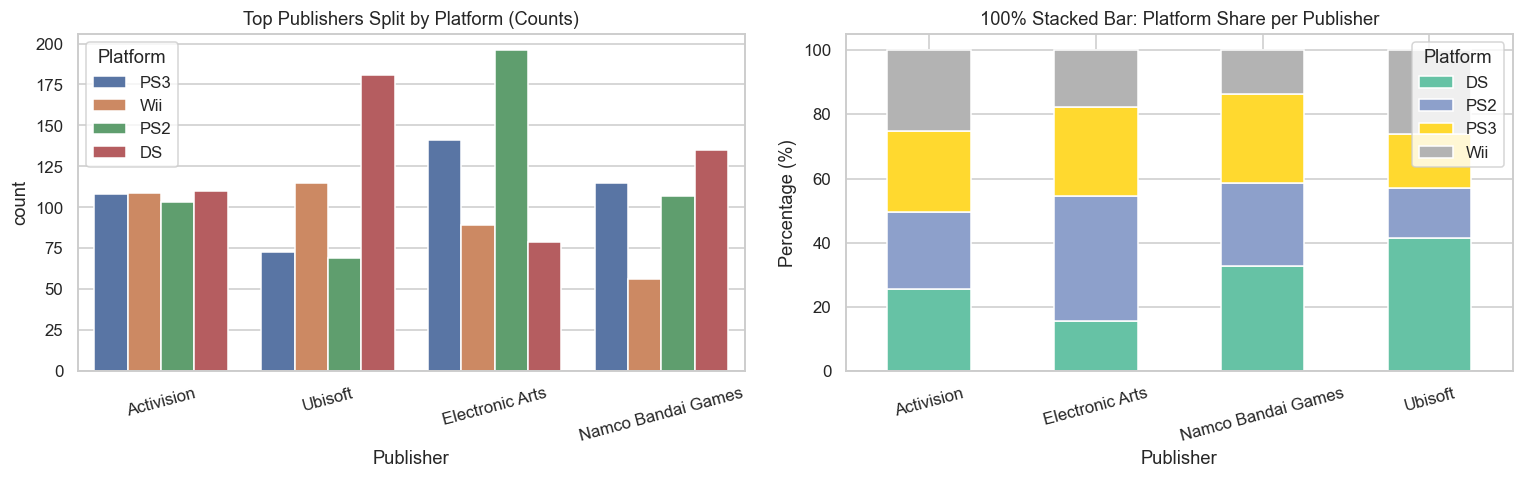

In [8]:
tp = df["Publisher"].value_counts().head(4).index
tl = df["Platform"].value_counts().head(4).index
sub_cat = df[df["Publisher"].isin(tp) & df["Platform"].isin(tl)]

ct = pd.crosstab(sub_cat["Publisher"], sub_cat["Platform"])
ct_pct = ct.div(ct.sum(axis=1), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.countplot(x="Publisher", hue="Platform", data=sub_cat, ax=axes[0])
axes[0].set_title("Top Publishers Split by Platform (Counts)")
axes[0].tick_params(axis="x", rotation=15)

ct_pct.plot(kind="bar", stacked=True, ax=axes[1], colormap="Set2")
axes[1].set_title("100% Stacked Bar: Platform Share per Publisher")
axes[1].set_ylabel("Percentage (%)")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()


## 5. Pair Plot & Joint Plot


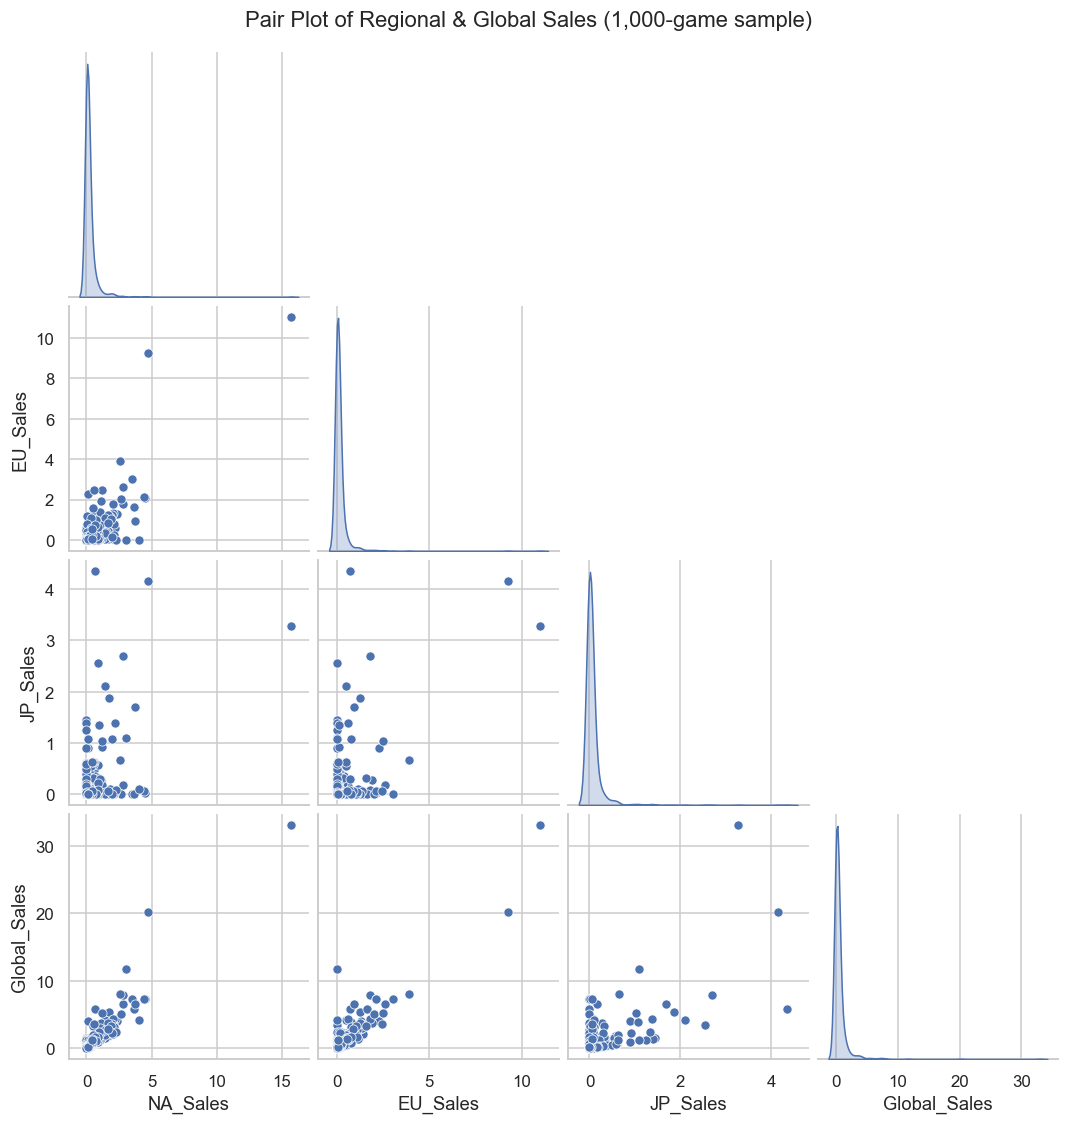

In [9]:
# Sample 1000 rows for fast pairplot
sns.pairplot(
    df[["NA_Sales", "EU_Sales", "JP_Sales", "Global_Sales"]].sample(1000, random_state=42),
    diag_kind="kde", corner=True
)
plt.suptitle("Pair Plot of Regional & Global Sales (1,000-game sample)", y=1.02)
plt.show()


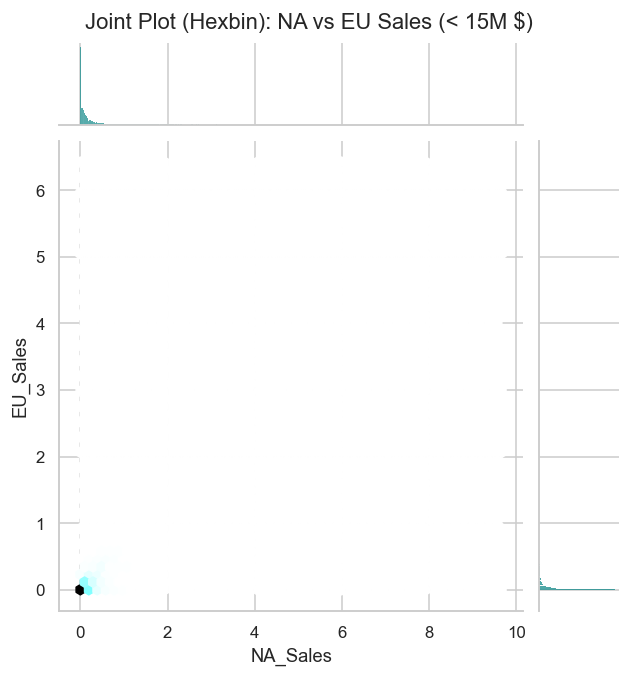

In [10]:
# Joint plot: scatter + marginal distributions
sns.jointplot(data=df[df["Global_Sales"] < 15], x="NA_Sales", y="EU_Sales", kind="hex", color="teal")
plt.suptitle("Joint Plot (Hexbin): NA vs EU Sales (< 15M $)", y=1.02)
plt.show()
